In [40]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [41]:
GROUP = "C1"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C1_10,27,"[DATA/TRAINING/C1/C1_10/IMG_6497.HEIC, DATA/TR..."
1,C1_11,26,"[DATA/TRAINING/C1/C1_11/IMG_6665.HEIC, DATA/TR..."
2,C1_12,27,"[DATA/TRAINING/C1/C1_12/IMG_6797.HEIC, DATA/TR..."
3,C1_13,27,"[DATA/TRAINING/C1/C1_13/IMG_6929.HEIC, DATA/TR..."
4,C1_14,26,"[DATA/TRAINING/C1/C1_14/IMG_7188.HEIC, DATA/TR..."
5,C1_15,28,"[DATA/TRAINING/C1/C1_15/IMG_7316.HEIC, DATA/TR..."
6,C1_16,27,"[DATA/TRAINING/C1/C1_16/IMG_7446.HEIC, DATA/TR..."


In [42]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [43]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [44]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_7446.HEIC')

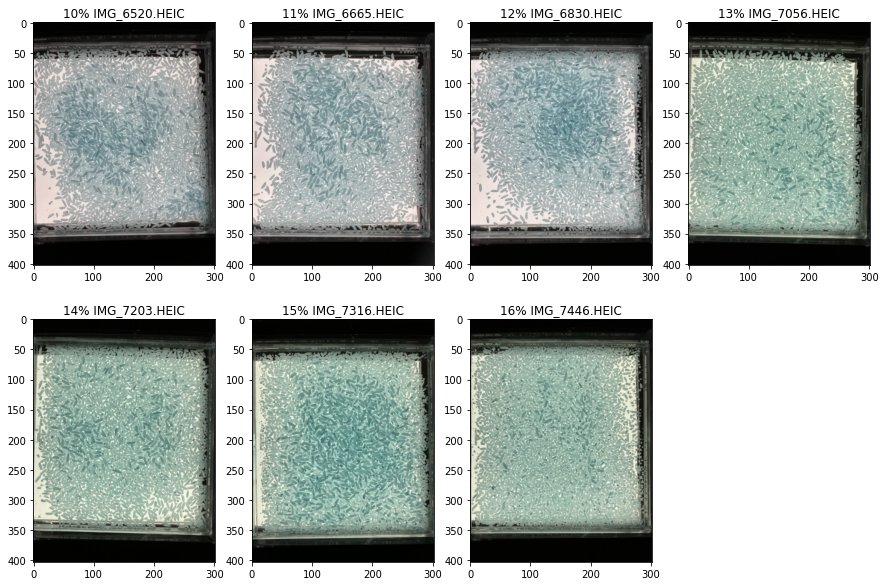

In [45]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [46]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [47]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.002848,351.312921,0.962184,4645.041341,0.213191,244.325843,18228.852441,7.886621,11.715812,0.000204,...,0.000138,5.355863,-0.295013,0.992203,3,120,90,3,IMG_6497.HEIC,10
1,0.002935,392.257678,0.958360,4710.064992,0.213873,243.724345,18448.002291,7.942231,11.757193,0.000207,...,0.000139,5.388062,-0.298918,0.992851,3,120,90,3,IMG_6498.HEIC,10
2,0.002937,401.442790,0.960479,5078.813181,0.215753,241.328558,19913.809934,7.882332,11.662677,0.000212,...,0.000146,5.336842,-0.294267,0.992014,3,120,90,3,IMG_6499.HEIC,10
3,0.002920,346.135861,0.965686,5043.623391,0.216100,242.037172,19828.357701,7.924333,11.706548,0.000212,...,0.000150,5.307238,-0.302408,0.993095,3,120,90,3,IMG_6500.HEIC,10
4,0.002700,351.735487,0.965051,5032.161748,0.214168,241.089794,19776.911506,7.867701,11.691436,0.000211,...,0.000148,5.330624,-0.298019,0.992498,3,120,90,3,IMG_6501.HEIC,10
5,0.003008,347.676217,0.962479,4633.107858,0.213486,244.948502,18184.755213,7.983518,11.780370,0.000199,...,0.000126,5.459375,-0.296554,0.992783,3,120,90,3,IMG_6502.HEIC,10
6,0.003101,396.837547,0.961115,5102.759062,0.220475,240.670880,20014.198703,7.832532,11.604505,0.000211,...,0.000134,5.385658,-0.284738,0.990602,3,120,90,3,IMG_6503.HEIC,10
7,0.003033,425.119288,0.957903,5049.285287,0.212108,241.952060,19772.021859,7.877267,11.696496,0.000198,...,0.000130,5.405286,-0.287094,0.991105,3,120,90,3,IMG_6504.HEIC,10
8,0.002983,486.482772,0.951447,5009.775240,0.214753,241.156554,19552.618187,7.987662,11.800843,0.000198,...,0.000124,5.507446,-0.288560,0.991748,3,120,90,3,IMG_6505.HEIC,10
9,0.003098,484.300468,0.951482,4990.900861,0.213482,240.619382,19479.302976,7.981186,11.798361,0.000196,...,0.000124,5.501381,-0.289603,0.991863,3,120,90,3,IMG_6506.HEIC,10


# Classification

In [48]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [49]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [50]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [51]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [52]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [53]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.833333,0.809524,0.821256,HRLK,C1,RF_C,3,120,90,3
1,2,0.736842,0.800000,0.761905,0.780488,HRLK,C1,RF_C,3,120,90,3
2,3,0.631579,0.719048,0.619048,0.665311,HRLK,C1,RF_C,3,120,90,3
3,4,0.684211,0.759524,0.690476,0.723356,HRLK,C1,RF_C,3,120,90,3
4,5,0.736842,0.788095,0.738095,0.762276,HRLK,C1,RF_C,3,120,90,3
5,6,0.842105,0.833333,0.833333,0.833333,HRLK,C1,RF_C,3,120,90,3
6,7,0.684211,0.752381,0.690476,0.720101,HRLK,C1,RF_C,3,120,90,3
7,8,0.736842,0.800000,0.738095,0.767802,HRLK,C1,RF_C,3,120,90,3
8,9,0.833333,0.857143,0.809524,0.832653,HRLK,C1,RF_C,3,120,90,3
9,10,0.722222,0.742857,0.714286,0.728291,HRLK,C1,RF_C,3,120,90,3


In [54]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C1,RF_C,0.739766,0.740476,0.763487,0.788571


### MLP Classifier

In [55]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [56]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [57]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.821429,0.785714,0.803175,HRLK,C1,MLP_C,3,120,90,3
1,2,0.789474,0.845238,0.785714,0.814390,HRLK,C1,MLP_C,3,120,90,3
2,3,0.894737,0.904762,0.904762,0.904762,HRLK,C1,MLP_C,3,120,90,3
3,4,0.789474,0.859524,0.738095,0.794195,HRLK,C1,MLP_C,3,120,90,3
4,5,0.631579,0.657143,0.619048,0.637527,HRLK,C1,MLP_C,3,120,90,3
5,6,0.894737,0.928571,0.904762,0.916512,HRLK,C1,MLP_C,3,120,90,3
6,7,0.789474,0.871429,0.785714,0.826355,HRLK,C1,MLP_C,3,120,90,3
7,8,0.684211,0.759524,0.690476,0.723356,HRLK,C1,MLP_C,3,120,90,3
8,9,0.722222,0.797619,0.714286,0.753656,HRLK,C1,MLP_C,3,120,90,3
9,10,0.722222,0.797619,0.714286,0.753656,HRLK,C1,MLP_C,3,120,90,3


In [58]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C1,MLP_C,0.77076,0.764286,0.792758,0.824286


### XGBoost Classifier

In [59]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [60]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.907143,0.809524,0.855558,HRLK,C1,XGB_C,3,120,90,3
1,2,0.736842,0.680952,0.714286,0.697221,HRLK,C1,XGB_C,3,120,90,3
2,3,0.789474,0.809524,0.785714,0.797441,HRLK,C1,XGB_C,3,120,90,3
3,4,0.736842,0.761905,0.761905,0.761905,HRLK,C1,XGB_C,3,120,90,3
4,5,0.894737,0.916667,0.904762,0.910675,HRLK,C1,XGB_C,3,120,90,3
5,6,0.842105,0.869048,0.833333,0.850816,HRLK,C1,XGB_C,3,120,90,3
6,7,0.789474,0.845238,0.785714,0.814390,HRLK,C1,XGB_C,3,120,90,3
7,8,0.842105,0.880952,0.833333,0.856481,HRLK,C1,XGB_C,3,120,90,3
8,9,0.666667,0.738095,0.666667,0.700565,HRLK,C1,XGB_C,3,120,90,3
9,10,0.722222,0.788095,0.738095,0.762276,HRLK,C1,XGB_C,3,120,90,3


In [61]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C1,XGB_C,0.786257,0.783333,0.800733,0.819762


# External validation

In [62]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C1_10,5,"[DATA/TEST/C1/C1_10/IMG_6492.HEIC, DATA/TEST/C..."
1,C1_11,5,"[DATA/TEST/C1/C1_11/IMG_6655.HEIC, DATA/TEST/C..."
2,C1_12,5,"[DATA/TEST/C1/C1_12/IMG_6788.HEIC, DATA/TEST/C..."
3,C1_13,5,"[DATA/TEST/C1/C1_13/IMG_6917.HEIC, DATA/TEST/C..."
4,C1_14,5,"[DATA/TEST/C1/C1_14/IMG_7178.HEIC, DATA/TEST/C..."
5,C1_15,5,"[DATA/TEST/C1/C1_15/IMG_7304.HEIC, DATA/TEST/C..."
6,C1_16,5,"[DATA/TEST/C1/C1_16/IMG_7436.HEIC, DATA/TEST/C..."


In [63]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [64]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [65]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.002876,440.888483,0.955523,4956.365326,0.213428,242.924251,19384.572820,7.890858,11.723247,0.000199,...,0.000132,5.458234,-0.297160,0.992577,3,120,90,3,IMG_6492.HEIC,10
1,0.002773,374.888202,0.961355,4850.382955,0.214837,240.887079,19026.643616,7.804064,11.635826,0.000207,...,0.000144,5.356793,-0.294690,0.991954,3,120,90,3,IMG_6493.HEIC,10
2,0.003120,420.958427,0.959640,5215.029534,0.224827,243.561423,20439.159710,8.149297,11.865932,0.000216,...,0.000138,5.446981,-0.315902,0.994910,3,120,90,3,IMG_6494.HEIC,10
3,0.002575,407.947940,0.959545,5042.043775,0.218704,240.089700,19760.227160,8.052969,11.838711,0.000204,...,0.000139,5.414194,-0.307916,0.994034,3,120,90,3,IMG_6495.HEIC,10
4,0.004869,375.399345,0.961175,4834.552297,0.217312,243.230993,18962.809845,7.826941,11.649786,0.000206,...,0.000147,5.316985,-0.299158,0.992515,3,120,90,3,IMG_6496.HEIC,10
0,0.012424,266.670506,0.975110,5356.968882,0.230976,260.772378,21161.205024,7.613343,11.290685,0.000214,...,0.000142,5.319073,-0.306286,0.992503,3,120,90,3,IMG_6655.HEIC,11
1,0.011066,301.983614,0.971000,5206.574693,0.230432,260.260206,20524.315158,7.655581,11.333700,0.000214,...,0.000141,5.347638,-0.308961,0.992923,3,120,90,3,IMG_6657.HEIC,11
2,0.011103,352.698408,0.967628,5447.555219,0.229976,254.893539,21437.522468,7.661307,11.397556,0.000206,...,0.000132,5.461061,-0.298151,0.991840,3,120,90,3,IMG_6659.HEIC,11
3,0.010553,375.289607,0.964652,5308.557411,0.219736,257.717322,20858.940037,7.805226,11.627012,0.000190,...,0.000126,5.500288,-0.306476,0.993301,3,120,90,3,IMG_6662.HEIC,11
4,0.010604,337.976685,0.968659,5391.952450,0.240524,262.392978,21229.833115,7.901752,11.602065,0.000216,...,0.000137,5.457084,-0.317582,0.994502,3,120,90,3,IMG_6663.HEIC,11


In [66]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [67]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [68]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [69]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [70]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.67      0.40      0.50         5
     Class 3       0.56      1.00      0.71         5
     Class 4       0.44      0.80      0.57         5
     Class 5       1.00      0.60      0.75         5
     Class 6       1.00      0.20      0.33         5

    accuracy                           0.71        35
   macro avg       0.81      0.71      0.70        35
weighted avg       0.81      0.71      0.70        35



## MLP

In [71]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [72]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       1.00      0.40      0.57         5
     Class 3       0.45      1.00      0.62         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      0.40      0.57         5

    accuracy                           0.80        35
   macro avg       0.89      0.80      0.80        35
weighted avg       0.89      0.80      0.80        35



## XGBC

In [73]:
y_pred = modelXGBC.predict(X_test_scale) 

In [74]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.50      0.60      0.55         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.50      0.80      0.62         5
     Class 5       1.00      0.60      0.75         5
     Class 6       0.50      0.20      0.29         5

    accuracy                           0.69        35
   macro avg       0.71      0.69      0.68        35
weighted avg       0.71      0.69      0.68        35

